# 7장 · 케라스 완전 정복

케라스의 **겉(쉬운 API)부터 속(훈련 루프)까지** 한 겹씩 벗겨 보는 노트북이에요.
위에서부터 실행하면 '복잡성의 단계적 공개' 순서 그대로 내려가요. CPU로 전체 약 3~5분.

| 절 | 내용 | 그림 노트 카드 · 내 필기 |
|---|---|---|
| 1 | 모델을 만드는 3가지 방법 · 섞어 쓰기 | 7.1 복잡성의 단계적 공개 |
| 2 | Sequential: 가중치는 **언제** 생기나 (`build`) | 7.1 |
| 3 | 함수형 API: 고객 문의 티켓 (다중 입력 · 다중 출력) · 중간 층 꺼내기 | 7.2.2 함수형 API |
| 4 | 서브클래싱 · 섞어 쓰기 | 7.1 |
| 5 | 내장 루프: 사용자 정의 지표 · 콜백 (EarlyStopping · Checkpoint · 직접 만든 콜백) | 7.3.2 콜백 |
| 6 | 사용자 정의 훈련 루프 · 지표 저수준 사용 · `train_step()` 오버라이드 | 7.4 사용자 정의 훈련 루프 |

### 백엔드는 왜 파이토치?

7.4의 훈련 루프는 **그레이디언트 계산 부분만** 백엔드마다 달라요. 이 노트북은 그 부분을 세 백엔드 모두 써 두었어요.
기본값은 루프가 가장 읽기 쉬운 **파이토치**(`loss.backward()`). 3장에서 JAX를 썼으니, 스터디 중에 `"jax"`나 `"tensorflow"`로 바꿔서 다시 돌려 보며 비교해 보세요.

🔍 = 내부 들여다보기, 💬 = 설명 포인트.

## 0. 준비

- `KERAS_BACKEND`는 **`import keras` 전에** 정해요. 바꾸려면 커널 재시작 → 이 셀부터 다시.
- 시드를 고정해서 실행할 때마다 거의 같은 결과가 나오게 해요 (CPU 연산 순서 때문에 소수점 끝자리는 조금 달라질 수 있어요).

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # "tensorflow" / "torch" / "jax"

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

keras.utils.set_random_seed(42)
plt.rcParams["font.family"] = "Malgun Gothic"     # 그래프 한글 깨짐 방지 (윈도)
plt.rcParams["axes.unicode_minus"] = False
print("keras", keras.__version__, "| backend =", keras.backend.backend())

keras 3.15.1 | backend = torch

In [2]:
def plot_history(histories, key="val_loss", title=None, ylim=None):
    """여러 history를 한 그래프에 겹쳐 그리기. histories = {"이름": history}"""
    plt.figure(figsize=(7, 3.6))
    for name, h in histories.items():
        v = h.history[key]
        plt.plot(range(1, len(v) + 1), v, "-o", ms=3, label=name)
    plt.xlabel("에포크"); plt.ylabel(key); plt.title(title or key)
    if ylim: plt.ylim(*ylim)
    plt.legend(); plt.grid(alpha=.3); plt.show()

## 1. 복잡성의 단계적 공개 (§7.1)

| | 쉬움 ← | → 자유도 높음 | |
|---|---|---|---|
| **모델 만들기** | `Sequential` | 함수형 API | 서브클래싱 (`keras.Model` 상속) |
| **훈련하기** | `fit()` | `fit()` + 사용자 정의 지표 · 콜백 · `train_step()` | 완전히 직접 짠 루프 |

- 원칙: **쉬운 방법으로 시작**, 필요할 때만 한 단계씩 내려가요.
- 단계끼리 섞을 수 있어요. 예) 서브클래싱한 층을 함수형 모델 안에서 사용.

## 2. Sequential 모델 — 가중치는 언제 생기나 (§7.2.1)

💬 **설명 포인트**: `Dense(64)`를 만들 때 가중치 행렬의 크기를 정할 수 있을까?

> 못 정해요. 커널 shape = `(입력 특성 수, 64)`인데, 입력 특성 수를 아직 모르니까요.
> 그래서 케라스는 **처음 입력을 보는 순간** `build()`를 불러 가중치를 만들어요 (3장 '층과 모델' 카드).

In [3]:
model = keras.Sequential([
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
print("만든 직후 weights:", model.weights)       # 아직 없음!
print("built?", model.built)

model.build(input_shape=(None, 3))               # 또는 실제 데이터를 한 번 넣기
for w in model.weights:
    print(f"{w.path:28s} {tuple(w.shape)}")

만든 직후 weights: []
built? False
sequential/dense/kernel      (3, 64)
sequential/dense/bias        (64,)
sequential/dense_1/kernel    (64, 10)
sequential/dense_1/bias      (10,)

In [4]:
# 처음부터 입력 크기를 알려 주면 바로 만들어지고 summary()도 바로 볼 수 있어요
model = keras.Sequential(name="my_example_model")
model.add(keras.Input(shape=(3,)))
model.add(layers.Dense(64, activation="relu", name="my_first_layer"))
model.add(layers.Dense(10, activation="softmax", name="my_last_layer"))
model.summary()
print("파라미터 직접 계산:", 3 * 64 + 64, "+", 64 * 10 + 10, "=", 3 * 64 + 64 + 64 * 10 + 10)

Model: "my_example_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ my_first_layer (Dense)          │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ my_last_layer (Dense)           │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 906 (3.54 KB)

 Trainable params: 906 (3.54 KB)

 Non-trainable params: 0 (0.00 B)

파라미터 직접 계산: 256 + 650 = 906

## 3. 함수형 API — 고객 문의 티켓 모델 (§7.2.2)

**입력 3개** → 합치기 → **출력 2개**

| 입력 | shape | 출력 | 활성화 · 손실 |
|---|---|---|---|
| 제목 (멀티-핫) | `(10000,)` | 우선순위 (0~1 점수) | sigmoid · `mean_squared_error` |
| 본문 (멀티-핫) | `(10000,)` | 담당 부서 (4개 중 하나) | softmax · `categorical_crossentropy` |
| 태그 (멀티-핫) | `(100,)` | | |

층을 **함수처럼 호출**해서 선으로 잇는다고 생각하면 돼요: `x = layer(x)`.

In [5]:
vocabulary_size, num_tags, num_departments = 10000, 100, 4

title = keras.Input(shape=(vocabulary_size,), name="title")
text_body = keras.Input(shape=(vocabulary_size,), name="text_body")
tags = keras.Input(shape=(num_tags,), name="tags")

features = layers.Concatenate()([title, text_body, tags])
features = layers.Dense(64, activation="relu", name="dense_features")(features)

priority = layers.Dense(1, activation="sigmoid", name="priority")(features)
department = layers.Dense(num_departments, activation="softmax", name="department")(features)

model = keras.Model(inputs=[title, text_body, tags], outputs=[priority, department])
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ title (InputLayer)  │ (None, 10000)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_body           │ (None, 10000)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tags (InputLayer)   │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 20100)     │          0 │ title[0][0],      │
│ (Concatenate)       │                   │            │ text_body[0][0],  │
│                     │                   │            │ tags[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_features      │ (None, 64)        │  1,286,464 │ concatenate[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ priority (Dense)    │ (None, 1)         │         65 │ dense_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ department (Dense)  │ (None, 4)         │        260 │ dense_features[0… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,286,789 (4.91 MB)

 Trainable params: 1,286,789 (4.91 MB)

 Non-trainable params: 0 (0.00 B)

### 🔍 내부 들여다보기 ① `keras.Input`이 돌려주는 건 진짜 데이터가 아니다

`title`은 **심볼릭 텐서**(KerasTensor)예요. 값은 없고 shape · dtype만 있는 '자리 표시자'라서, 층을 호출하면 출력 shape만 계산해서 넘겨요.
그래서 데이터를 넣기도 전에 모델 그래프와 summary가 완성돼요.

In [6]:
print(type(title).__name__, title.shape, title.dtype)
print("features:", features.shape, "| priority:", priority.shape, "| department:", department.shape)

for layer in model.layers:
    ins = layer.input if isinstance(layer.input, list) else [layer.input]
    print(f"{layer.name:16s} 입력 {[tuple(i.shape) for i in ins]} → 출력 {tuple(layer.output.shape)}")

KerasTensor (None, 10000) float32
features: (None, 64) | priority: (None, 1) | department: (None, 4)
title            입력 [] → 출력 (None, 10000)
text_body        입력 [] → 출력 (None, 10000)
tags             입력 [] → 출력 (None, 100)
concatenate      입력 [(None, 10000), (None, 10000), (None, 100)] → 출력 (None, 20100)
dense_features   입력 [(None, 20100)] → 출력 (None, 64)
priority         입력 [(None, 64)] → 출력 (None, 1)
department       입력 [(None, 64)] → 출력 (None, 4)

In [7]:
# 가짜 데이터로 훈련 → 평가 → 예측 (입력 · 타깃을 '리스트'나 '이름 딕셔너리'로)
num_samples = 1280
rng = np.random.default_rng(0)
title_data = rng.integers(0, 2, size=(num_samples, vocabulary_size)).astype("float32")
text_body_data = rng.integers(0, 2, size=(num_samples, vocabulary_size)).astype("float32")
tags_data = rng.integers(0, 2, size=(num_samples, num_tags)).astype("float32")
priority_data = rng.random(size=(num_samples, 1)).astype("float32")
department_data = keras.utils.to_categorical(rng.integers(0, num_departments, size=num_samples), num_departments)

model.compile(optimizer="adam",
              loss={"priority": "mean_squared_error", "department": "categorical_crossentropy"},
              metrics={"priority": ["mean_absolute_error"], "department": ["accuracy"]})
model.fit({"title": title_data, "text_body": text_body_data, "tags": tags_data},
          {"priority": priority_data, "department": department_data}, epochs=1, verbose=2)
priority_preds, department_preds = model.predict([title_data, text_body_data, tags_data], verbose=0)
print("priority_preds", priority_preds.shape, "department_preds", department_preds.shape)

40/40 - 5s - 118ms/step - department_accuracy: 0.2625 - department_loss: 8.8321 - loss: 9.1529 - priority_loss: 0.3208 - priority_mean_absolute_error: 0.4903
priority_preds (1280, 1) department_preds (1280, 4)

💬 **설명 포인트**: 출력이 2개면 손실은 어떻게 하나로 합칠까?

> 각 출력의 손실을 따로 계산하고 **더해서**(기본 가중치 1) 하나의 스칼라로 만든 뒤 그 합을 최소화해요. `loss_weights`로 비중을 바꿀 수 있어요.

### 🔍 내부 들여다보기 ② 중간 층 출력 꺼내기 · 그래프 확장

함수형 모델은 **층 그래프가 데이터 구조로 남아 있어서**, 중간 노드를 그대로 꺼내 새 모델을 만들 수 있어요.

In [8]:
# 중간 특성(dense_features)을 출력으로 하는 '특성 추출기'
feature_extractor = keras.Model(inputs=model.inputs, outputs=model.get_layer("dense_features").output)
print("특성 추출기 출력:", feature_extractor.predict([title_data[:2], text_body_data[:2], tags_data[:2]], verbose=0).shape)

# 기존 모델에 출력 하나 추가: 문제 난이도 (빠름 · 보통 · 어려움)
f = model.layers[4].output
difficulty = layers.Dense(3, activation="softmax", name="difficulty")(f)
new_model = keras.Model(inputs=[title, text_body, tags], outputs=[priority, department, difficulty])
print("새 모델 출력 shape:", [tuple(o.shape) for o in new_model.outputs])

# 가중치를 공유하는가? (같은 층 객체를 재사용 → 같은 변수)
print("dense_features 커널을 공유?", new_model.get_layer("dense_features").kernel is model.get_layer("dense_features").kernel)

특성 추출기 출력: (2, 64)
새 모델 출력 shape: [(None, 1), (None, 4), (None, 3)]
dense_features 커널을 공유? True

In [9]:
try:
    keras.utils.plot_model(model, "ticket_classifier.png", show_shapes=True)
    from IPython.display import Image, display; display(Image("ticket_classifier.png"))
except Exception as e:
    print("plot_model 은 pydot + graphviz 설치가 필요해요 →", type(e).__name__)
    print("설치 후: pip install pydot  +  https://graphviz.org/download/")

plot_model 은 pydot + graphviz 설치가 필요해요 → ImportError
설치 후: pip install pydot  +  https://graphviz.org/download/

## 4. 서브클래싱 · 섞어 쓰기 (§7.2.3)

- `__init__()`에서 층을 만들고, `call()`에서 **파이썬 코드로 자유롭게** 정방향 계산을 써요.
- 대가: 층 그래프가 데이터 구조로 남지 않아요 → **호출 전엔 summary 불가**, 중간 층 꺼내기 불가.

In [10]:
class CustomerTicketModel(keras.Model):
    def __init__(self, num_departments):
        super().__init__()
        self.concat_layer = layers.Concatenate()
        self.mixing_layer = layers.Dense(64, activation="relu")
        self.priority_scorer = layers.Dense(1, activation="sigmoid")
        self.department_classifier = layers.Dense(num_departments, activation="softmax")

    def call(self, inputs):
        features = self.concat_layer([inputs["title"], inputs["text_body"], inputs["tags"]])
        features = self.mixing_layer(features)
        return self.priority_scorer(features), self.department_classifier(features)

sub = CustomerTicketModel(num_departments=4)
print("호출 전 weights 개수:", len(sub.weights))
p, d = sub({"title": title_data[:2], "text_body": text_body_data[:2], "tags": tags_data[:2]})
print("호출 후 weights 개수:", len(sub.weights), "| 출력", tuple(p.shape), tuple(d.shape))

호출 전 weights 개수: 0
호출 후 weights 개수: 6 | 출력 (2, 1) (2, 4)

In [11]:
# 섞어 쓰기: 서브클래싱한 층을 함수형 모델 안에서
class Classifier(keras.Model):
    def __init__(self, num_classes=2):
        super().__init__()
        if num_classes == 2:
            num_units, activation = 1, "sigmoid"
        else:
            num_units, activation = num_classes, "softmax"
        self.dense = layers.Dense(num_units, activation=activation)

    def call(self, inputs):
        return self.dense(inputs)

inputs = keras.Input(shape=(3,))
x = layers.Dense(64, activation="relu")(inputs)
outputs = Classifier(num_classes=10)(x)
mixed = keras.Model(inputs=inputs, outputs=outputs)
print("함수형 안의 서브클래싱 모델 → 출력", mixed.output.shape)

함수형 안의 서브클래싱 모델 → 출력 (None, 10)

## 5. 내장 훈련 루프 확장하기 — 지표와 콜백 (§7.3)

공통 실습: MNIST + 드롭아웃 있는 작은 모델 (책과 같은 `get_mnist_model`).

In [12]:
from keras.datasets import mnist

def get_mnist_model():
    inputs = keras.Input(shape=(28 * 28,))
    features = layers.Dense(512, activation="relu")(inputs)
    features = layers.Dropout(0.5)(features)
    outputs = layers.Dense(10, activation="softmax")(features)
    return keras.Model(inputs, outputs)

(images, labels), (test_images, test_labels) = mnist.load_data()
images = images.reshape((60000, 28 * 28)).astype("float32") / 255
test_images = test_images.reshape((10000, 28 * 28)).astype("float32") / 255
train_images, val_images = images[10000:], images[:10000]
train_labels, val_labels = labels[10000:], labels[:10000]
print(train_images.shape, val_images.shape, test_images.shape)

(50000, 784) (10000, 784) (10000, 784)

### 5-1. 사용자 정의 지표 — 지표는 '상태를 가진 객체'

지표는 배치마다 값을 **누적**했다가(`update_state`) 마지막에 계산해요(`result`). 그래서 변수(상태)를 가져요.

In [13]:
from keras import ops

class RootMeanSquaredError(keras.metrics.Metric):
    def __init__(self, name="rmse", **kwargs):
        super().__init__(name=name, **kwargs)
        self.mse_sum = self.add_weight(name="mse_sum", initializer="zeros")
        self.total_samples = self.add_weight(name="total_samples", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = ops.one_hot(y_true, num_classes=ops.shape(y_pred)[1])
        mse = ops.sum(ops.square(y_true - y_pred))
        self.mse_sum.assign_add(mse)
        self.total_samples.assign_add(ops.shape(y_pred)[0])

    def result(self):
        return ops.sqrt(self.mse_sum / self.total_samples)

    def reset_state(self):
        self.mse_sum.assign(0.)
        self.total_samples.assign(0.)

model = get_mnist_model()
model.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy",
              metrics=["accuracy", RootMeanSquaredError()])
model.fit(train_images, train_labels, epochs=2, validation_data=(val_images, val_labels), verbose=2)
print(model.evaluate(test_images, test_labels, verbose=0, return_dict=True))

Epoch 1/2
1563/1563 - 102s - 65ms/step - accuracy: 0.9129 - loss: 0.2946 - rmse: 0.3629 - val_accuracy: 0.9568 - val_loss: 0.1539 - val_rmse: 0.2585
Epoch 2/2
1563/1563 - 73s - 47ms/step - accuracy: 0.9546 - loss: 0.1597 - rmse: 0.2648 - val_accuracy: 0.9662 - val_loss: 0.1188 - val_rmse: 0.2279
{'accuracy': 0.9682000279426575, 'loss': 0.10377020388841629, 'rmse': 0.21951118111610413}

### 5-2. 콜백 — 훈련을 지켜보다가 알아서 행동하는 감시자

| 콜백 | 하는 일 |
|---|---|
| `EarlyStopping` | 지표가 `patience` 에포크 동안 안 좋아지면 **멈춤** |
| `ModelCheckpoint` | 에포크 끝마다 저장. `save_best_only=True`면 **최고일 때만** |
| 직접 만든 콜백 | `on_epoch_end`, `on_batch_end` 같은 시점에 원하는 코드 실행 |

In [14]:
import tempfile
ckpt_path = os.path.join(tempfile.gettempdir(), "checkpoint_path.keras")
callbacks_list = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=1),
    keras.callbacks.ModelCheckpoint(filepath=ckpt_path, monitor="val_loss", save_best_only=True, verbose=1),
]
model = get_mnist_model()
model.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = model.fit(train_images, train_labels, epochs=10, callbacks=callbacks_list,
              validation_data=(val_images, val_labels), verbose=2)
print(f"\n10 에포크 중 {len(h.history['loss'])} 에포크에서 멈춤")
best = keras.models.load_model(ckpt_path)
print("저장된 최고 모델 val_loss:", round(best.evaluate(val_images, val_labels, verbose=0)[0], 4))

Epoch 1/10

Epoch 1: val_loss improved from None to 0.15244, saving model to C:\Users\a\AppData\Local\Temp\checkpoint_path.keras

Epoch 1: finished saving model to C:\Users\a\AppData\Local\Temp\checkpoint_path.keras
1563/1563 - 33s - 21ms/step - accuracy: 0.9106 - loss: 0.2967 - val_accuracy: 0.9551 - val_loss: 0.1524
Epoch 2/10

Epoch 2: val_loss improved from 0.15244 to 0.11172, saving model to C:\Users\a\AppData\Local\Temp\checkpoint_path.keras

Epoch 2: finished saving model to C:\Users\a\AppData\Local\Temp\checkpoint_path.keras
1563/1563 - 21s - 14ms/step - accuracy: 0.9527 - loss: 0.1625 - val_accuracy: 0.9674 - val_loss: 0.1117
Epoch 3/10

Epoch 3: val_loss improved from 0.11172 to 0.10121, saving model to C:\Users\a\AppData\Local\Temp\checkpoint_path.keras

Epoch 3: finished saving model to C:\Users\a\AppData\Local\Temp\checkpoint_path.keras
1563/1563 - 13s - 8ms/step - accuracy: 0.9620 - loss: 0.1327 - val_accuracy: 0.9722 - val_loss: 0.1012
Epoch 4/10

Epoch 4: val_loss did n

### 🔍 내부 들여다보기: 직접 만든 콜백으로 **배치마다** 손실 기록

`fit()`이 보여 주는 건 에포크 평균이에요. 콜백을 걸면 그 안의 배치 단위 움직임을 볼 수 있어요.

  [콜백] 에포크 1 끝: 배치 1563개 지남, val_loss=0.1644
  [콜백] 에포크 2 끝: 배치 3126개 지남, val_loss=0.1314
  [콜백] 에포크 3 끝: 배치 4689개 지남, val_loss=0.1074

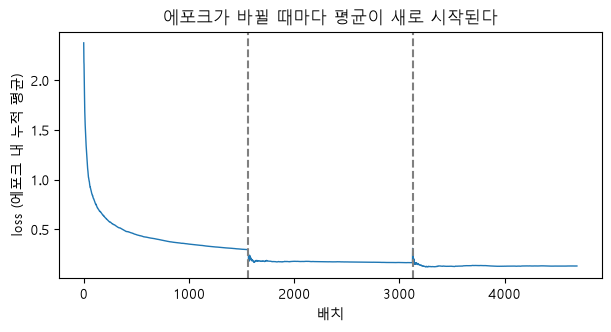

In [15]:
class LossHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.per_batch_losses = []
        self.epoch_ends = []

    def on_batch_end(self, batch, logs=None):
        self.per_batch_losses.append(logs.get("loss"))   # 주의: 에포크 시작부터의 '누적 평균'

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_ends.append(len(self.per_batch_losses))
        print(f"  [콜백] 에포크 {epoch + 1} 끝: 배치 {self.epoch_ends[-1]}개 지남, val_loss={logs['val_loss']:.4f}")

lh = LossHistory()
model = get_mnist_model()
model.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_images, train_labels, epochs=3, callbacks=[lh], validation_data=(val_images, val_labels), verbose=0)

plt.figure(figsize=(7, 3.2))
plt.plot(lh.per_batch_losses, lw=1)
for e in lh.epoch_ends[:-1]: plt.axvline(e, ls="--", c="gray")
plt.xlabel("배치"); plt.ylabel("loss (에포크 내 누적 평균)"); plt.title("에포크가 바뀔 때마다 평균이 새로 시작된다"); plt.show()

## 6. 사용자 정의 훈련 루프 (§7.4)

### 6-1. `training=True / False`

드롭아웃 · 배치 정규화는 훈련과 추론에서 다르게 동작해요. 그래서 직접 짠 루프에선 **꼭** `model(x, training=True)`로 불러야 해요.

In [16]:
m = get_mnist_model()
x1 = val_images[:1]
a = ops.convert_to_numpy(m(x1, training=False)); b = ops.convert_to_numpy(m(x1, training=False))
c = ops.convert_to_numpy(m(x1, training=True)); d = ops.convert_to_numpy(m(x1, training=True))
print("추론 모드 두 번 → 같은가?", np.allclose(a, b))
print("훈련 모드 두 번 → 같은가?", np.allclose(c, d), "(드롭아웃 마스크가 매번 달라서)")

추론 모드 두 번 → 같은가? True
훈련 모드 두 번 → 같은가? False (드롭아웃 마스크가 매번 달라서)

### 6-2. 지표의 저수준 사용: `update_state()` → `result()` → `reset_state()`

5-1에서 만든 지표가 `fit()` 안에서 실제로 이렇게 쓰여요.

In [17]:
metric = keras.metrics.SparseCategoricalAccuracy()
targets = np.array([0, 1, 2]); predictions = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]], dtype="float32")
metric.update_state(targets, predictions)
print("1번 누적 후:", float(metric.result()))
metric.update_state(np.array([0, 0, 0]), predictions)       # 이번엔 1/3만 맞음
print("2번 누적 후:", float(metric.result()), "← (3 + 1) / 6")
print("내부 상태 변수:", [(v.name, float(ops.convert_to_numpy(v))) for v in metric.variables])
metric.reset_state(); print("reset 후:", float(metric.result()))

mean_tracker = keras.metrics.Mean()
for v in [0, 1, 2, 3, 4]: mean_tracker.update_state(v)
print("Mean 지표:", float(mean_tracker.result()))

1번 누적 후: 1.0
2번 누적 후: 0.6666666865348816 ← (3 + 1) / 6
내부 상태 변수: [('total', 4.0), ('count', 6.0)]
reset 후: 0.0
Mean 지표: 2.0

### 6-3. 완전한 훈련 루프 직접 짜기 — `fit()`의 속

그림 노트 7.4 카드의 5단계:
**① 배치 뽑기 → ② 정방향 `model(x, training=True)` → ③ 손실 → ④ 그레이디언트 → ⑤ `optimizer.apply()`**

④만 백엔드마다 달라요. 아래 셀은 지금 백엔드(`keras.backend.backend()`)에 맞는 가지를 골라 실행해요.

| 백엔드 | ④ 그레이디언트 |
|---|---|
| 텐서플로 | `with tf.GradientTape() as tape:` → `tape.gradient(loss, weights)` |
| 파이토치 | `model.zero_grad()` → `loss.backward()` → `v.value.grad` |
| JAX | 상태를 **인자로 넘기는** `model.stateless_call()` + `jax.value_and_grad` (3장의 함수형 철학) |

In [18]:
model = get_mnist_model()
loss_fn = keras.losses.SparseCategoricalCrossentropy()
optimizer = keras.optimizers.RMSprop()
metrics = [keras.metrics.SparseCategoricalAccuracy()]
loss_tracking_metric = keras.metrics.Mean()
BACKEND = keras.backend.backend()

if BACKEND == "torch":
    import torch

    def train_step(inputs, targets):
        predictions = model(inputs, training=True)              # ② 정방향
        loss = loss_fn(targets, predictions)                    # ③ 손실
        model.zero_grad()                                       # .grad 누적 방지 (3장!)
        loss.backward()                                         # ④ 역전파
        gradients = [v.value.grad for v in model.trainable_weights]
        with torch.no_grad():
            optimizer.apply(gradients, model.trainable_weights) # ⑤ 업데이트
        return loss, predictions

elif BACKEND == "tensorflow":
    import tensorflow as tf

    def train_step(inputs, targets):
        with tf.GradientTape() as tape:                         # ④ 기록 시작
            predictions = model(inputs, training=True)          # ②
            loss = loss_fn(targets, predictions)                # ③
        gradients = tape.gradient(loss, model.trainable_weights)
        optimizer.apply(gradients, model.trainable_weights)     # ⑤
        return loss, predictions

elif BACKEND == "jax":
    import jax

    def compute_loss_and_updates(trainable_vars, non_trainable_vars, inputs, targets):
        predictions, non_trainable_vars = model.stateless_call(
            trainable_vars, non_trainable_vars, inputs, training=True)   # ② (상태를 인자로)
        return loss_fn(targets, predictions), (predictions, non_trainable_vars)   # ③

    grad_fn = jax.value_and_grad(compute_loss_and_updates, has_aux=True)  # ④ 함수 → 그레이디언트 함수
    optimizer.build(model.trainable_variables)
    jax_state = [[v.value for v in model.trainable_variables],
                 [v.value for v in model.non_trainable_variables],
                 [v.value for v in optimizer.variables]]

    def train_step(inputs, targets):
        tv, ntv, ov = jax_state
        (loss, (predictions, ntv)), grads = grad_fn(tv, ntv, inputs, targets)
        tv, ov = optimizer.stateless_apply(ov, grads, tv)                  # ⑤ 새 상태를 '반환'받음
        jax_state[:] = [tv, ntv, ov]
        return loss, predictions

def sync_jax_state():
    """JAX는 상태를 밖에서 들고 다녔으니, 끝나면 모델 변수에 다시 써 넣어요."""
    if BACKEND == "jax":
        for v, val in zip(model.trainable_variables, jax_state[0]): v.assign(val)
        for v, val in zip(model.non_trainable_variables, jax_state[1]): v.assign(val)

print("이번 실행의 그레이디언트 방식:", BACKEND)

이번 실행의 그레이디언트 방식: torch

In [19]:
batch_size, epochs = 128, 3
for epoch in range(epochs):
    for m in metrics + [loss_tracking_metric]: m.reset_state()           # 에포크마다 지표 초기화
    perm = np.random.default_rng(epoch).permutation(len(train_images))
    for i in range(0, len(train_images), batch_size):                     # ① 배치 뽑기
        idx = perm[i:i + batch_size]
        x = ops.convert_to_tensor(train_images[idx]); y = ops.convert_to_tensor(train_labels[idx])
        loss, preds = train_step(x, y)
        for m in metrics: m.update_state(y, preds)
        loss_tracking_metric.update_state(loss)
    print(f"에포크 {epoch + 1}: loss {float(loss_tracking_metric.result()):.4f} | "
          f"accuracy {float(metrics[0].result()):.4f}")

sync_jax_state()
val_preds = model.predict(val_images, verbose=0)
print("검증 정확도:", round(float((val_preds.argmax(axis=1) == val_labels).mean()), 4))

에포크 1: loss 0.3459 | accuracy 0.8985
에포크 2: loss 0.1677 | accuracy 0.9496
에포크 3: loss 0.1289 | accuracy 0.9620
검증 정확도: 0.9705

💬 **설명 포인트**: 이 루프와 `model.fit()`은 무엇이 다를까?

> 계산은 같아요. `fit()`은 여기에 **진행 표시줄, 콜백, 검증, 분산 훈련, 컴파일 최적화**(XLA · `jit`)를 얹어 줄 뿐이에요.
> 직접 짜면 이 모든 걸 직접 챙겨야 해요 → 그래서 보통은 6-4처럼 **훈련 스텝만** 바꿔요.

### 6-4. `train_step()` 오버라이드 — 스텝만 바꾸고 `fit()`의 편의는 그대로

In [20]:
loss_fn = keras.losses.SparseCategoricalCrossentropy()
loss_tracker = keras.metrics.Mean(name="loss")

class CustomModel(keras.Model):
    @property
    def metrics(self):
        return [loss_tracker]          # 여기 적은 지표는 에포크마다 fit()이 reset_state() 해 줌

    if BACKEND == "torch":
        def train_step(self, data):
            inputs, targets = data
            predictions = self(inputs, training=True)
            loss = loss_fn(targets, predictions)
            self.zero_grad()
            loss.backward()
            gradients = [v.value.grad for v in self.trainable_weights]
            with torch.no_grad():
                self.optimizer.apply(gradients, self.trainable_weights)
            loss_tracker.update_state(loss)
            return {"loss": loss_tracker.result()}

    elif BACKEND == "tensorflow":
        def train_step(self, data):
            inputs, targets = data
            with tf.GradientTape() as tape:
                predictions = self(inputs, training=True)
                loss = loss_fn(targets, predictions)
            gradients = tape.gradient(loss, self.trainable_weights)
            self.optimizer.apply(gradients, self.trainable_weights)
            loss_tracker.update_state(loss)
            return {"loss": loss_tracker.result()}

    elif BACKEND == "jax":
        def compute_loss_and_updates(self, trainable_variables, non_trainable_variables, inputs, targets):
            predictions, non_trainable_variables = self.stateless_call(
                trainable_variables, non_trainable_variables, inputs, training=True)
            return loss_fn(targets, predictions), non_trainable_variables

        def train_step(self, state, data):       # JAX: 상태를 받고 새 상태를 돌려줌
            (trainable_variables, non_trainable_variables, optimizer_variables, metrics_variables) = state
            inputs, targets = data
            grad_fn = jax.value_and_grad(self.compute_loss_and_updates, has_aux=True)
            (loss, non_trainable_variables), grads = grad_fn(
                trainable_variables, non_trainable_variables, inputs, targets)
            trainable_variables, optimizer_variables = self.optimizer.stateless_apply(
                optimizer_variables, grads, trainable_variables)
            new_metrics_vars = loss_tracker.stateless_update_state(metrics_variables, loss)
            logs = {"loss": loss_tracker.stateless_result(new_metrics_vars)}
            return logs, (trainable_variables, non_trainable_variables, optimizer_variables, new_metrics_vars)

inputs = keras.Input(shape=(28 * 28,))
features = layers.Dense(512, activation="relu")(inputs)
features = layers.Dropout(0.5)(features)
outputs = layers.Dense(10, activation="softmax")(features)
model = CustomModel(inputs, outputs)
model.compile(optimizer=keras.optimizers.RMSprop())      # 손실은 train_step 안에서 직접 계산
model.fit(train_images, train_labels, epochs=3, verbose=2)

Epoch 1/3
1563/1563 - 12s - 8ms/step - loss: 0.2947
Epoch 2/3
1563/1563 - 17s - 11ms/step - loss: 0.1581
Epoch 3/3
1563/1563 - 25s - 16ms/step - loss: 0.1313

---
## 정리 · 스스로 설명해 보기

1. Sequential · 함수형 · 서브클래싱을 언제 고르나? 각각 못 하는 것은? → ______
2. `keras.Input`이 돌려주는 객체의 정체는? → ______
3. 다중 출력 모델의 손실은 어떻게 합쳐지나? → ______
4. `EarlyStopping(patience=1)` + `ModelCheckpoint(save_best_only=True)` 조합의 의미는? → ______
5. 훈련 루프 5단계와, 백엔드마다 다른 단계는? → ______
6. 지표가 `update_state / result / reset_state` 세 메서드를 갖는 이유는? → ______